In [44]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

Load the clip and the samplerate of the clip

In [45]:
aMajor, samplerate = librosa.load('clips/Amaj.wav', sr=None)

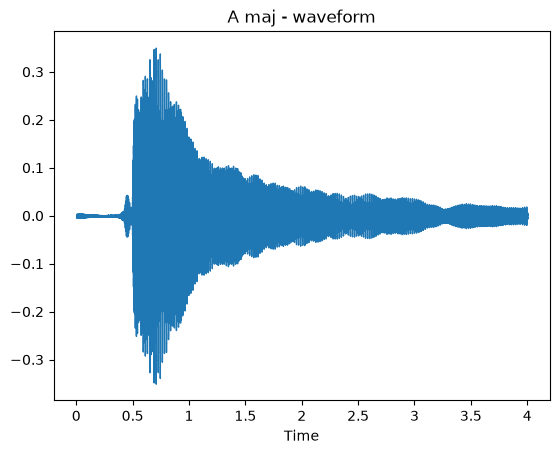

In [46]:
librosa.display.waveshow(aMajor, sr=samplerate)
plt.title('A maj - waveform')
plt.show()

Pass the loaded clip into librosa to produce a chromagram, display the chromagram using librosa.display.specshow, which displays the chromagram w/ automatic axis assignment and labels

In [47]:
chroma = librosa.feature.chroma_cqt(y=aMajor, sr=samplerate)

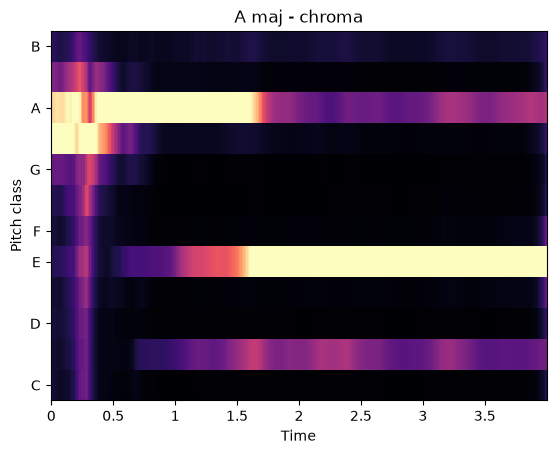

In [48]:
librosa.display.specshow(chroma, y_axis='chroma', x_axis='time', sr=samplerate)
plt.title('A maj - chroma')
plt.show()

A small template of chords represented as arrays split into 12 pitch classifications

In [49]:
# 0=C, 1=C#, 2=D, 3=D#, 4=E, 5=F, 6=F#, 7=G, 8=G#, 9=A, 10=A#, 11=B, exactly like the 12 pitch classes from a chroma
chord_templates = {
    'C':  [1,0,0,0,1,0,0,1,0,0,0,0],
    'G':  [0,0,1,0,0,0,0,1,0,0,0,1],
    'D':  [0,0,1,0,0,0,1,0,0,1,0,0],
    'Em': [0,0,0,0,1,0,0,1,0,0,0,1],
    'Am': [1,0,0,0,1,0,0,0,0,1,0,0],
    'F':  [1,0,0,0,0,1,0,0,0,1,0,0],
    'A':  [0,1,0,0,1,0,0,0,0,1,0,0],
}

Chord Detection function, takes in chroma_frame, which is a frame of the clip and performs cosin similarity on the audio clips chroma frame against the template chords. The output is the best matched chord, with the name taken from the template and the certainty of the algorithms assumption

In [50]:
def detect_chord(chroma_frame):
    '''
    :param chroma_frame: section of audio as a chroma, to analyse the notes present and find the best
                        chord match
    :return: the best match chord, taken from every frame
    '''

    best_match = None
    best_score = -1

    for name, template in chord_templates.items():
        #Cosine similarity: dot product of the the chroma_frame vector and the template of chords vector divided by the product of their magnitudes
        score = np.dot(chroma_frame, template) / (np.linalg.norm(chroma_frame) * np.linalg.norm(template))
        if score > best_score:
            best_match = name
            best_score = score

    return best_match, best_score

avg_chroma takes 12 snapshots of the chroma vector, axis=1 enables it so that we get the average chroma for each of the 12 pitch classifications (1 per row)

In [51]:
avg_chroma = np.mean(chroma, axis=1)
chord, score = detect_chord(avg_chroma)
# print w/ score rounded to two decimal places
print(f"The chord is: {chord} , Certainty: {round(score, 2)}")

The chord is: A , Certainty: 0.92


In [52]:
cToG, sampleRate2 = librosa.load('clips/C_to_G.wav', sr=None)

In [55]:
# Compute a separate chromagram for this clip
chroma2 = librosa.feature.chroma_cqt(y=cToG, sr=sampleRate2)

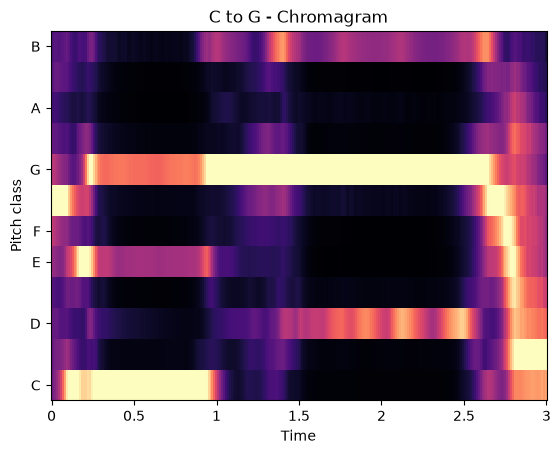

In [58]:
librosa.display.specshow(chroma2, y_axis='chroma', x_axis='time', sr=samplerate)
plt.title('C to G - Chromagram')
plt.show()